# Lab 10 — Completed Exercises

**Student:** Abdulaziz Saqer BinRuqush  
**Student ID:** 2230007229

Instructor notebook: [Lab10_Introduction_to_Machine_Translation-2.ipynb](https://github.com/MohammedMosuily/NLP_lab10)  
Source commit: `25bd7ba4c84748f246809556d372f083fb1a379e`

Run the setup commands in the course README before running all cells.
Instructor examples and task instructions are retained below.


In [1]:
from pathlib import Path
import os
import sys
import random
import numpy as np
import pandas as pd
from IPython.display import display

LAB_DIR = Path.cwd()
if not (LAB_DIR / 'Lab10_Introduction_to_Machine_Translation-2.ipynb').is_file():
    LAB_DIR = LAB_DIR / "Lab10"
if not (LAB_DIR / 'Lab10_Introduction_to_Machine_Translation-2.ipynb').is_file():
    raise FileNotFoundError("Run from the course root or this lab's folder.")
PROJECT_ROOT = LAB_DIR.parent
os.environ.setdefault("KAGGLEHUB_CACHE", str(PROJECT_ROOT / ".cache" / "kagglehub"))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")   # keep TensorFlow's C++ start-up chatter out of the outputs
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from course_data import dataset_file
random.seed(42)
np.random.seed(42)
print("Lab 10 | Abdulaziz Saqer BinRuqush | 2230007229")

Lab 10 | Abdulaziz Saqer BinRuqush | 2230007229


# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

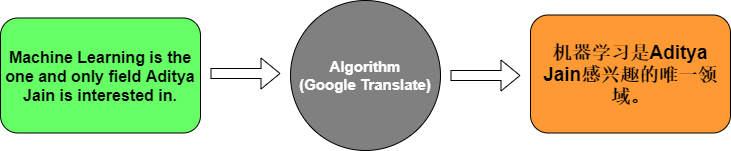

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [2]:
#!pip install tensorflow

In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [4]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [5]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [6]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [7]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.0000e+00 - loss: 2.4852

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0000e+00 - loss: 2.4852 - val_accuracy: 0.0000e+00 - val_loss: 2.4873


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5714 - loss: 2.4773

...

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8571 - loss: 0.4735

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8571 - loss: 0.4735 - val_accuracy: 0.0000e+00 - val_loss: 5.0752


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - accuracy: 0.5714 - loss: 1.9343

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step - accuracy: 0.5714 - loss: 1.9343


Test Accuracy: 0.5714285969734192


In [8]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step


Input: How are you?
Translation: comment va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


In [9]:
# Look inside the toy model trained above: what does each layer receive and return?
print("Padded English input     :", eng_padded.shape, "(sentences, words)")
embedded = model.layers[0](eng_padded)
print("After Embedding          :", embedded.shape, "(sentences, words, 64-dimensional vector per word)")
encoded = model.layers[1](embedded)
print("After Encoder LSTM       :", encoded.shape, "(sentences, 64) - one summary vector per sentence")
repeated = model.layers[2](encoded)
print("After RepeatVector       :", repeated.shape, "(sentence summary copied once per French word)")
decoded = model.layers[3](repeated)
print("After Decoder LSTM       :", decoded.shape, "(sentences, French words, 64)")
probabilities = model.layers[4](decoded)
print("After Dense + softmax    :", probabilities.shape, "(sentences, French words, French vocabulary)")
print("\nSoftmax output sums to 1 for every word position:",
      np.allclose(probabilities.numpy().sum(axis=-1), 1.0, atol=1e-4))
print("First embedding vector of the word 'hello' (first 5 of 64 numbers):",
      np.round(model.layers[0](np.array([[eng_word_index['hello']]])).numpy()[0, 0, :5], 3))

Padded English input     : (3, 6) (sentences, words)
After Embedding          : (3, 6, 64) (sentences, words, 64-dimensional vector per word)


After Encoder LSTM       : (3, 64) (sentences, 64) - one summary vector per sentence
After RepeatVector       : (3, 7, 64) (sentence summary copied once per French word)
After Decoder LSTM       : (3, 7, 64) (sentences, French words, 64)
After Dense + softmax    : (3, 7, 12) (sentences, French words, French vocabulary)

Softmax output sums to 1 for every word position: True
First embedding vector of the word 'hello' (first 5 of 64 numbers): [ 0.008  0.016  0.004 -0.021  0.032]


**Task 1 answers** (numbering follows the instructor's list)

1. **What does the Embedding layer do to a word index?** It looks the integer index up in a trainable
   table and returns a dense vector (64 numbers in this model) for that word. An index such as `5` is just a
   label with no meaning, while its vector is learned during training so that words used in similar ways
   end up with similar vectors. The shapes printed above show `(sentences, words)` becoming
   `(sentences, words, 64)`.
3. **What is the role of the Encoder LSTM?** It reads the embedded English words one at a time and keeps a
   running memory of what it has read. Its final output is a fixed-size vector (64 numbers) that summarizes
   the whole English sentence: its words, their order and their meaning. Everything the decoder knows about
   the source sentence comes from this vector.
5. **What does the Decoder LSTM do?** It takes the encoder's summary (copied once per output position by
   `RepeatVector`) and unrolls it into a sequence of hidden states, one per French word position
   (`return_sequences=True`). Each state is the information needed to choose the French word at that
   position, taking the earlier positions into account.
8. **Why do we use `softmax` in the final layer?** The `Dense` layer turns each hidden state into one score per
   French vocabulary word. `softmax` converts those scores into probabilities that are positive and sum to 1
   (verified above), so the model outputs a probability distribution over the French vocabulary at every
   position. That is what the `sparse_categorical_crossentropy` loss needs for training, and at inference
   the word with the highest probability (`argmax`) is chosen.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

### Task 2 solution: an English → French translation model

The toy model above fits three sentences. For the Kaggle English–French dataset the same encoder–decoder
idea is used, with three changes that make it a real translator:

- **Teacher forcing.** The decoder receives the previous correct French word (starting from `<start>`) and
  predicts the next one, and ends with `<end>`. The toy model's `RepeatVector` design predicts every position
  from the same sentence summary and cannot condition on what it has already produced.
- **Word-by-word (greedy) decoding at inference**, with separate encoder and decoder-step models.
- **Held-out evaluation** with BLEU, token accuracy and example translations, instead of a single test sentence.

**CPU budget.** The model is trained on CPU, so sentence pairs are limited to at most 10 tokens on each
side (words and punctuation) and vocabularies are capped at the most frequent words of the training split.
The limits and the share of data they keep are printed below. Sentences are split by their English text so
that the same English sentence never appears in both training and test data.

In [10]:
import re
import unicodedata

path = dataset_file("translation", "eng_-french.csv")
raw = pd.read_csv(path)
raw.columns = ["english", "french"]
print(f"Dataset: {path.name}, {len(raw):,} sentence pairs")
print("Missing values:", int(raw.isna().sum().sum()), "| exact duplicate pairs:", int(raw.duplicated().sum()))
display(raw.sample(8, random_state=42).reset_index(drop=True))

Dataset: eng_-french.csv, 175,621 sentence pairs
Missing values: 0 | exact duplicate pairs: 0


,english,french
0,Take a seat.,Prends place !
1,I wish Tom was here.,J'aimerais que Tom soit là.
2,How did the audition go?,Comment s'est passée l'audition ?
3,I've no friend to talk to about my problems.,Je n'ai pas d'ami avec lequel je puisse m'entr...
4,I really like this skirt. Can I try it on?,"J'aime beaucoup cette jupe, puis-je l'essayer ?"
5,What happened to him?,Que lui est-il arrivé ?
6,Take any two cards you like.,Prends deux cartes de ton choix.
7,I'm not scared to die.,Je ne crains pas de mourir.


In [11]:
MAX_LEN = 10   # maximum tokens per sentence on each side


def tokenize(sentence):
    """Lowercase, normalize Unicode, and split into words, French elisions (l', j', ...) and punctuation."""
    sentence = unicodedata.normalize("NFC", sentence).lower()
    return re.findall(r"\w+'|\w+|[^\w\s]", sentence)


def detokenize(tokens):
    """Join tokens back into readable text."""
    text = " ".join(tokens)
    text = re.sub(r"(\w')\s+", r"\1", text)      # l' aide -> l'aide
    text = re.sub(r"\s+([,.)])", r"\1", text)     # remove the space before , . )
    text = re.sub(r"(\()\s+", r"\1", text)
    text = re.sub(r"\s*-\s*", "-", text)         # as - tu -> as-tu
    return text[:1].upper() + text[1:]


pairs = raw.dropna().copy()
pairs["en_tokens"] = pairs["english"].map(tokenize)
pairs["fr_tokens"] = pairs["french"].map(tokenize)
lengths = pd.DataFrame({"English": pairs["en_tokens"].str.len(), "French": pairs["fr_tokens"].str.len()})
print(lengths.describe().loc[["mean", "50%", "max"]].round(1))

kept = pairs[(lengths["English"] <= MAX_LEN) & (lengths["French"] <= MAX_LEN)].reset_index(drop=True)
print(f"\nPairs with at most {MAX_LEN} tokens on both sides: {len(kept):,} of {len(pairs):,} "
      f"({len(kept) / len(pairs):.1%}); distinct English sentences: {kept['english'].str.lower().nunique():,}")
print("Tokenization example:", tokenize("Je n'ai pas pu m'endormir à cause du bruit."))
print("Detokenized         :", detokenize(tokenize("Je n'ai pas pu m'endormir à cause du bruit.")))

      English  French
mean      7.6     8.5
50%       7.0     8.0
max      51.0    63.0

Pairs with at most 10 tokens on both sides: 135,641 of 175,621 (77.2%); distinct English sentences: 94,550
Tokenization example: ['je', "n'", 'ai', 'pas', 'pu', "m'", 'endormir', 'à', 'cause', 'du', 'bruit', '.']
Detokenized         : Je n'ai pas pu m'endormir à cause du bruit.


In [12]:
# Split by distinct English sentence (80 / 10 / 10) so that no English sentence is shared between splits.
keys = kept["english"].str.lower().str.strip()
unique_keys = np.array(sorted(keys.unique()))
rng = np.random.RandomState(42)
rng.shuffle(unique_keys)
n_unique = len(unique_keys)
train_keys = set(unique_keys[: int(0.8 * n_unique)])
val_keys = set(unique_keys[int(0.8 * n_unique): int(0.9 * n_unique)])
split = np.where(keys.isin(train_keys), "train", np.where(keys.isin(val_keys), "validation", "test"))
train_df = kept[split == "train"].reset_index(drop=True)
val_df = kept[split == "validation"].reset_index(drop=True)
test_df = kept[split == "test"].reset_index(drop=True)
print(f"train: {len(train_df):,} pairs | validation: {len(val_df):,} pairs | test: {len(test_df):,} pairs")
overlap = set(train_df["english"].str.lower().str.strip()) & set(test_df["english"].str.lower().str.strip())
print("English sentences shared by train and test:", len(overlap))
assert not overlap

train: 108,313 pairs | validation: 13,681 pairs | test: 13,647 pairs
English sentences shared by train and test: 0


In [13]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

tf.keras.utils.set_random_seed(42)
EN_VOCAB, FR_VOCAB = 6000, 8000      # most frequent training-set words kept; the rest become <unk>
FR_LEN = MAX_LEN + 2                  # French sequences also hold <start> and <end>


def english_text(tokens):
    return " ".join(tokens)


def french_text(tokens):
    return "<start> " + " ".join(tokens) + " <end>"


tokenizer_en = Tokenizer(num_words=EN_VOCAB, oov_token="<unk>", filters="", lower=False)
tokenizer_fr = Tokenizer(num_words=FR_VOCAB, oov_token="<unk>", filters="", lower=False)
tokenizer_en.fit_on_texts(train_df["en_tokens"].map(english_text))   # fitted on training data only
tokenizer_fr.fit_on_texts(train_df["fr_tokens"].map(french_text))


def encode(df):
    # Encoder input: pre-padded (as in the toy example) so the last LSTM step sees the last real word.
    encoder = pad_sequences(tokenizer_en.texts_to_sequences(df["en_tokens"].map(english_text)), maxlen=MAX_LEN)
    decoder = pad_sequences(tokenizer_fr.texts_to_sequences(df["fr_tokens"].map(french_text)),
                            maxlen=FR_LEN, padding="post")
    return encoder, decoder


train_enc, train_dec = encode(train_df)
val_enc, val_dec = encode(val_df)
test_enc, test_dec = encode(test_df)

en_vocab_size = min(EN_VOCAB, len(tokenizer_en.word_index) + 1)
fr_vocab_size = min(FR_VOCAB, len(tokenizer_fr.word_index) + 1)
UNK_EN, UNK_FR = tokenizer_en.word_index["<unk>"], tokenizer_fr.word_index["<unk>"]
START_ID, END_ID = tokenizer_fr.word_index["<start>"], tokenizer_fr.word_index["<end>"]
print(f"English vocabulary: {en_vocab_size:,} ids (padding, <unk> and the most frequent words) "
      f"from {len(tokenizer_en.word_index) - 1:,} distinct training words")
print(f"French vocabulary : {fr_vocab_size:,} ids (padding, <unk>, <start>, <end> and the most frequent words) "
      f"from {len(tokenizer_fr.word_index) - 3:,} distinct training words")
print(f"Unknown-word rate on the test set: English {np.mean(test_enc[test_enc > 0] == UNK_EN):.2%}, "
      f"French {np.mean(test_dec[test_dec > 0] == UNK_FR):.2%}")
print("Example encoder input:", test_enc[0], "->", test_df.loc[0, "english"])
print("Example decoder input:", test_dec[0], "->", test_df.loc[0, "french"])

English vocabulary: 6,000 ids (padding, <unk> and the most frequent words) from 10,979 distinct training words
French vocabulary : 8,000 ids (padding, <unk>, <start>, <end> and the most frequent words) from 18,539 distinct training words
Unknown-word rate on the test set: English 1.44%, French 2.07%
Example encoder input: [   0    0    0    0    0    0    0    0 2949    2] -> Hi.
Example decoder input: [   2 3468   36    3    0    0    0    0    0    0    0    0] -> Salut!


In [14]:
EMBED_DIM, UNITS = 128, 256
Layers = tf.keras.layers

encoder_inputs = tf.keras.Input(shape=(MAX_LEN,), name="english_ids")
encoder_embedding = Layers.Embedding(en_vocab_size, EMBED_DIM, mask_zero=True, name="encoder_embedding")
encoder_lstm = Layers.LSTM(UNITS, return_state=True, name="encoder_lstm")
_, state_h, state_c = encoder_lstm(encoder_embedding(encoder_inputs))

decoder_inputs = tf.keras.Input(shape=(FR_LEN - 1,), name="french_ids_shifted")
decoder_embedding = Layers.Embedding(fr_vocab_size, EMBED_DIM, mask_zero=True, name="decoder_embedding")
decoder_lstm = Layers.LSTM(UNITS, return_sequences=True, return_state=True, name="decoder_lstm")
decoder_sequence, _, _ = decoder_lstm(decoder_embedding(decoder_inputs), initial_state=[state_h, state_c])
decoder_dense = Layers.Dense(fr_vocab_size, activation="softmax", name="french_word_probabilities")
decoder_outputs = decoder_dense(decoder_sequence)

nmt_model = tf.keras.Model([encoder_inputs, decoder_inputs], decoder_outputs, name="english_to_french")
nmt_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["sparse_categorical_accuracy"])
nmt_model.summary()

Model: "english_to_french"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english_ids         │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_ids_shifted  │ (None, 11)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, 10, 128)   │    768,000 │ english_ids[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 10)        │          0 │ english_ids[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, 11, 128)   │  1,024,000 │ french_ids_shift… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 256),     │    394,240 │ encoder_embeddin… │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 11, 256), │    394,240 │ decoder_embeddin… │
│                     │ (None, 256),      │            │ encoder_lstm[0][… │
│                     │ (None, 256)]      │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_word_probab… │ (None, 11, 8000)  │  2,056,000 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,636,480 (17.69 MB)

 Trainable params: 4,636,480 (17.69 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# Teacher forcing: the decoder input is the French sentence without its last token,
# and the target is the same sentence shifted one position to the left.
def decoder_pair(decoder_ids):
    return decoder_ids[:, :-1], decoder_ids[:, 1:, None]


train_dec_in, train_dec_out = decoder_pair(train_dec)
val_dec_in, val_dec_out = decoder_pair(val_dec)
test_dec_in, test_dec_out = decoder_pair(test_dec)

early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
history = nmt_model.fit(
    [train_enc, train_dec_in], train_dec_out,
    validation_data=([val_enc, val_dec_in], val_dec_out),
    batch_size=128, epochs=20, callbacks=[early_stopping], verbose=2)
print("Epochs run:", len(history.history["loss"]),
      "| best validation loss:", round(min(history.history["val_loss"]), 4))

Epoch 1/20


847/847 - 139s - 164ms/step - loss: 3.8471 - sparse_categorical_accuracy: 0.3815 - val_loss: 2.9918 - val_sparse_categorical_accuracy: 0.4673


Epoch 2/20


847/847 - 132s - 156ms/step - loss: 2.7043 - sparse_categorical_accuracy: 0.5126 - val_loss: 2.4049 - val_sparse_categorical_accuracy: 0.5457


Epoch 3/20


...

Epoch 15/20


847/847 - 144s - 170ms/step - loss: 0.6250 - sparse_categorical_accuracy: 0.8358 - val_loss: 1.3373 - val_sparse_categorical_accuracy: 0.7149


Epoch 16/20


847/847 - 140s - 165ms/step - loss: 0.5809 - sparse_categorical_accuracy: 0.8458 - val_loss: 1.3449 - val_sparse_categorical_accuracy: 0.7165


Epochs run: 16 | best validation loss: 1.3254


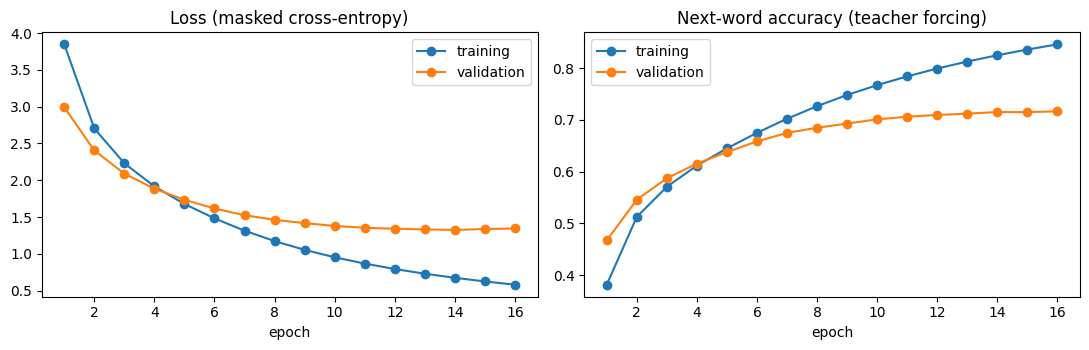

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
epochs = range(1, len(history.history["loss"]) + 1)
axes[0].plot(epochs, history.history["loss"], marker="o", label="training")
axes[0].plot(epochs, history.history["val_loss"], marker="o", label="validation")
axes[0].set_title("Loss (masked cross-entropy)")
axes[1].plot(epochs, history.history["sparse_categorical_accuracy"], marker="o", label="training")
axes[1].plot(epochs, history.history["val_sparse_categorical_accuracy"], marker="o", label="validation")
axes[1].set_title("Next-word accuracy (teacher forcing)")
for axis in axes:
    axis.set_xlabel("epoch")
    axis.legend()
plt.tight_layout()
plt.show()

In [17]:
# Inference models: the encoder turns an English sentence into LSTM states; the decoder step predicts one
# French word at a time from the previous word and the states.
encoder_model = tf.keras.Model(encoder_inputs, [state_h, state_c])

step_token = tf.keras.Input(shape=(1,), name="previous_french_word")
step_h = tf.keras.Input(shape=(UNITS,), name="state_h")
step_c = tf.keras.Input(shape=(UNITS,), name="state_c")
step_sequence, next_h, next_c = decoder_lstm(decoder_embedding(step_token), initial_state=[step_h, step_c])
decoder_step_model = tf.keras.Model([step_token, step_h, step_c], [decoder_dense(step_sequence), next_h, next_c])

index_to_french = {index: word for word, index in tokenizer_fr.word_index.items() if index < fr_vocab_size}


def greedy_decode(encoder_ids, max_steps=FR_LEN - 1):
    """Translate a batch of padded English id sequences; returns one list of French tokens per sentence."""
    h, c = encoder_model(encoder_ids, training=False)
    count = len(encoder_ids)
    previous = tf.constant(np.full((count, 1), START_ID))
    finished = np.zeros(count, dtype=bool)
    output = [[] for _ in range(count)]
    for _ in range(max_steps):
        probabilities, h, c = decoder_step_model([previous, h, c], training=False)
        probabilities = probabilities.numpy()[:, 0, :]
        probabilities[:, :2] = 0            # never output padding (0) or <unk> (1)
        chosen = probabilities.argmax(axis=-1)
        for row in range(count):
            if not finished[row]:
                if chosen[row] == END_ID:
                    finished[row] = True
                else:
                    output[row].append(index_to_french[chosen[row]])
        previous = tf.constant(chosen[:, None])
        if finished.all():
            break
    return output


def translate_sentence(sentence):
    """Translate one English sentence (at most 10 tokens) into French."""
    tokens = tokenize(sentence)
    ids = pad_sequences(tokenizer_en.texts_to_sequences([english_text(tokens)]), maxlen=MAX_LEN)
    return detokenize(greedy_decode(ids)[0])


for sentence in ["Hello.", "How are you?", "This is a machine translation example."]:
    print(f"{sentence:42} -> {translate_sentence(sentence)}")

Hello.                                     -> Bonjour.
How are you?                               -> Comment vous êtes-vous ?
This is a machine translation example.     -> C'est une image à la pizza.


In [18]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# Translate the complete held-out test set.
predicted_tokens = []
for start in range(0, len(test_enc), 512):
    predicted_tokens += greedy_decode(test_enc[start:start + 512])
reference_tokens = test_df["fr_tokens"].tolist()
assert len(predicted_tokens) == len(reference_tokens)

smooth = SmoothingFunction().method1
references = [[ref] for ref in reference_tokens]
bleu = {f"BLEU-{n}": corpus_bleu(references, predicted_tokens, weights=tuple([1 / n] * n), smoothing_function=smooth)
        for n in (1, 2, 3, 4)}
test_loss, test_accuracy = nmt_model.evaluate([test_enc, test_dec_in], test_dec_out, batch_size=256, verbose=0)
exact = np.mean([pred == ref for pred, ref in zip(predicted_tokens, reference_tokens)])

print(f"Test sentence pairs        : {len(test_df):,}")
for name, value in bleu.items():
    print(f"{name:27}: {value * 100:.1f}")
print(f"Exact-match translations   : {exact:.1%}")
print(f"Next-word accuracy (test)  : {test_accuracy:.1%}   masked loss: {test_loss:.3f}")

samples = test_df.sample(12, random_state=7).index
display(pd.DataFrame({
    "English": test_df.loc[samples, "english"].values,
    "Reference French": test_df.loc[samples, "french"].values,
    "Model translation": [detokenize(predicted_tokens[i]) for i in samples],
}))

Test sentence pairs        : 13,647
BLEU-1                     : 56.4
BLEU-2                     : 41.3
BLEU-3                     : 32.4
BLEU-4                     : 26.0
Exact-match translations   : 8.5%
Next-word accuracy (test)  : 71.9%   masked loss: 1.291


,English,Reference French,Model translation
0,I'm sorry if I frightened you.,Je suis désolé si je vous ai effrayées.,Je suis désolé si je vous ai entendu.
1,Did you find that helpful?,As-tu trouvé ça utile ?,As-tu trouvé ça ?
2,I could say a lot about this topic.,Je pourrais en dire beaucoup sur ce sujet.,Je pourrais entendre ça en tant que tout le mo...
3,We have checked.,Nous avons vérifié.,Nous avons des besoins.
4,Do I look like I'm busy?,Ai-je l'air d'être occupée ?,J'ai l'air si occupée ?
5,How much did you pay?,Combien avez-vous payé ?,Combien as-tu payé ?
6,They don't like to do that.,Ils n'aiment pas faire ça.,Ils ne peuvent pas faire cela.
7,You deserve a pay raise.,Vous méritez une augmentation.,Tu mérites des vêtements.
8,I hid behind the tree.,Je me cachai derrière l'arbre.,Je me suis caché derrière un arbre.
9,I have to talk to you alone.,Je dois te parler en tête à tête.,Je dois te parler seul.


In [19]:
# The use case: translate e-commerce content (product listings and customer reviews) into French.
def translate_text(text):
    """Translate a short listing or review sentence by sentence; sentences over 10 tokens are flagged."""
    translated = []
    for sentence in re.split(r"(?<=[.!?])\s+", text.strip()):
        if len(tokenize(sentence)) > MAX_LEN:
            translated.append(f"[sentence longer than {MAX_LEN} tokens, not translated]")
        else:
            translated.append(translate_sentence(sentence))
    return " ".join(translated)


ecommerce_texts = [
    ("Product listing", "Free shipping on all orders."),
    ("Product listing", "This phone is very cheap."),
    ("Product listing", "The book is on the table."),
    ("Customer review", "I love this car. It is very good."),
    ("Customer review", "The delivery was very fast."),
    ("Customer review", "I do not like it."),
    ("Customer review", "Thank you for your help."),
    ("Customer review", "Where can I buy this?"),
]
display(pd.DataFrame([(kind, text, translate_text(text)) for kind, text in ecommerce_texts],
                     columns=["Content type", "English", "French translation"]))

,Content type,English,French translation
0,Product listing,Free shipping on all orders.,Jouez dans les apparences !
1,Product listing,This phone is very cheap.,Ce restaurant est très bon.
2,Product listing,The book is on the table.,Le livre est sur la table.
3,Customer review,I love this car. It is very good.,J'adore cette voiture. C'est très bonne.
4,Customer review,The delivery was very fast.,La partie était très rapide.
5,Customer review,I do not like it.,Je n'en ai pas besoin.
6,Customer review,Thank you for your help.,Merci de votre aide.
7,Customer review,Where can I buy this?,Où puis-je acheter ceci ?


**Task 2 notes and limitations.**

- *Approach.* The pairs are cleaned and tokenized, split by distinct English sentence (80/10/10) so the test
  set contains no English sentence seen in training, and converted to integer sequences with Keras
  tokenizers fitted on the training split. An LSTM encoder–decoder with embeddings of size 128 and 256 LSTM
  units is trained with teacher forcing; validation loss controls early stopping and the best epoch is kept.
- *Results.* The BLEU scores, exact-match rate and next-word accuracy printed above come from translating
  the complete held-out test set. The model is a small word-level model, so it translates short, common
  sentences well and degrades quickly on rare words and longer sentences.
- *The e-commerce examples are of mixed quality.* Simple sentences close to the training data are often
  translated correctly, while others contain clear errors or change the meaning. The table above shows
  every output exactly as produced, without selecting favourable examples.
- *Limitations for the e-commerce use case.* Only sentences of at most 10 tokens are supported, and
  words outside the 6,000 most frequent English training words are mapped to `<unk>`. The dataset is made of
  everyday sentences, not shopping text, so product names, brand names and technical terms are not
  translated reliably. A production system would need domain data (product descriptions and reviews),
  subword tokenization and a larger or pretrained model.